In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from sklearn.preprocessing import StandardScaler

lines = np.loadtxt("USA_Housing.csv", delimiter=",",dtype='str')
header = lines[0]
lines = lines[1:].astype(float)
print('数据特征：',','.join(header[:-1]))
print('数据标签：',header[-1])
print('数据集大小：',len(lines))

ratio = 0.8
split = int(len(lines) * ratio)
lines = np.random.permutation(lines)
train = lines[:split]
test = lines[split:]

scaler = StandardScaler()
scaler.fit(train)
train = scaler.transform(train)
#使用训练集的参数来对测试集进行标准化
test = scaler.transform(test)

x_train, y_train = train[:, :-1], train[:, -1].flatten()
x_test, y_test = test[:, :-1], test[:, -1].flatten()


数据特征： Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population
数据标签： Price
数据集大小： 5000


In [2]:
X = np.concatenate([x_train, np.ones((len(x_train),1))], axis=-1)

theta = np.linalg.inv(X.T @ X) @ X.T @ y_train
print('回归系数:', theta)
#这里没有使用梯度下降，原因是在线性回归中，正规方程的解法是最优的
#不需要进行多次计算，并且一定有解
X_test = np.concatenate([x_test, np.ones((len(x_test),1))], axis=-1)
y_pred = X_test @ theta

#计算损失
rmse = np.sqrt(np.square(y_pred - y_test).mean())
print('均方根误差:', rmse)

回归系数: [6.47749390e-01 4.66003313e-01 3.47738776e-01 9.25702884e-03
 4.26062554e-01 1.69343706e-14]
均方根误差: 0.28248585254974967


In [3]:
from sklearn.linear_model import LinearRegression

linreg = LinearRegression()
linreg.fit(x_train, y_train)
print('回归系数:', linreg.coef_, linreg.intercept_)

y_pred = linreg.predict(x_test)

rmse = np.sqrt(np.square(y_pred - y_test).mean())
print('均方根误差:', rmse)


回归系数: [0.64774939 0.46600331 0.34773878 0.00925703 0.42606255] 1.695810245806952e-14
均方根误差: 0.2824858525497497


In [4]:
def batch_generator(x, y, batch_size,shuffle=True):
    batch_count = 0
    if shuffle:
        idx = np.random.permutation(len(x))
        x = x[idx]
        y = y[idx]
    while True:
        start = batch_count * batch_size
        end =min(start + batch_size,len(x))
        if start >= end:
            break
        batch_count += 1
        yield x[start:end], y[start:end]

In [5]:
def SGD(num_epochs,learning_rate,batch_size):
    X= np.concatenate([x_train, np.ones((len(x_train),1))], axis=-1)
    X_test = np.concatenate([x_test, np.ones((len(x_test),1))], axis=-1)
    #随机初始化theta
    theta = np.random.randn(X.shape[1])
    
    #随机梯度下降
    train_losses = []
    test_losses = []
    for i in range(num_epochs):
        batch_g = batch_generator(X,y_train,batch_size)
        train_loss = 0
        for x_batch,y_batch in batch_g:
            #计算梯度（除以batch内样本数，使学习率的含义不随batch_size变化）
            grad = x_batch.T@( x_batch @ theta - y_batch) / len(x_batch)
            #更新theta
            theta = theta - learning_rate * grad
            train_loss += np.square((x_batch @ theta - y_batch)).sum()
        
        train_loss = np.sqrt(train_loss / len(X))
        train_losses.append(train_loss)
        y_pred = X_test @ theta
        test_loss = np.sqrt(np.square(X_test @ theta - y_test).mean())
        test_losses.append(test_loss)

    print('回归系数:',theta)
    return theta,train_losses,test_losses
        

回归系数: [ 0.64528939  0.46719032  0.34889547  0.0107473   0.42654858 -0.00203356]


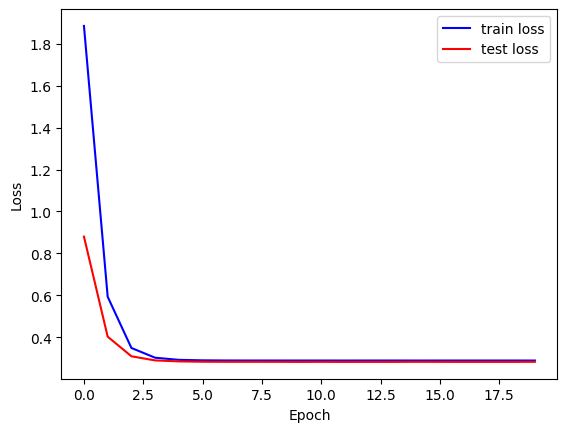

In [6]:
num_epochs = 20
learning_rate = 0.01
batch_size = 32

np.random.seed(0)

_,train_losses,test_losses = SGD(num_epochs,learning_rate,batch_size)

plt.plot(np.arange(num_epochs),train_losses,label='train loss',color='blue')
plt.plot(np.arange(num_epochs),test_losses,label='test loss',color='red')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

回归系数: [ 0.66363951  0.44792254  0.34659579  0.01227606  0.44350964 -0.00527924]
回归系数: [ 0.67859179  0.2886127   0.13020123  0.17979321  0.34249836 -0.17915936]


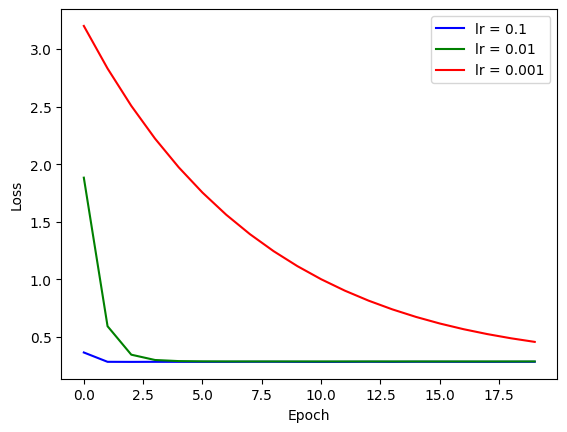

In [18]:
_,loss1,_ = SGD(num_epochs=num_epochs,learning_rate=0.1,batch_size=batch_size)
_,loss2,_ = SGD(num_epochs=num_epochs,learning_rate=0.001,batch_size=batch_size)
plt.plot(np.arange(num_epochs),loss1,label='lr = 0.1',color='blue')
plt.plot(np.arange(num_epochs),train_losses,label='lr = 0.01',color='green')
plt.plot(np.arange(num_epochs),loss2,label='lr = 0.001',color='red')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


回归系数: [ 5.92570625e+79  4.11612975e+79 -6.46377043e+79 -8.80680997e+79
  1.49285842e+79  1.16325249e+79]
[np.float64(1248.2387334554808), np.float64(459123.3187370822), np.float64(707856645426.8292), np.float64(6.422083322869161e+17), np.float64(5.149705493391227e+20), np.float64(3.2907097555523984e+22), np.float64(1.7459729620165813e+27), np.float64(4.558378826153123e+31), np.float64(1.2513008433860996e+37), np.float64(6.008071176426416e+43), np.float64(2.7366601546104856e+47), np.float64(8.118077452796512e+52), np.float64(1.218737135031926e+54), np.float64(1.4983752229272803e+57), np.float64(5.347193827898086e+60), np.float64(7.006680336024064e+65), np.float64(2.2692113393561278e+67), np.float64(7.027278498774374e+70), np.float64(2.7142714486889256e+76), np.float64(2.3407620796125374e+79)]


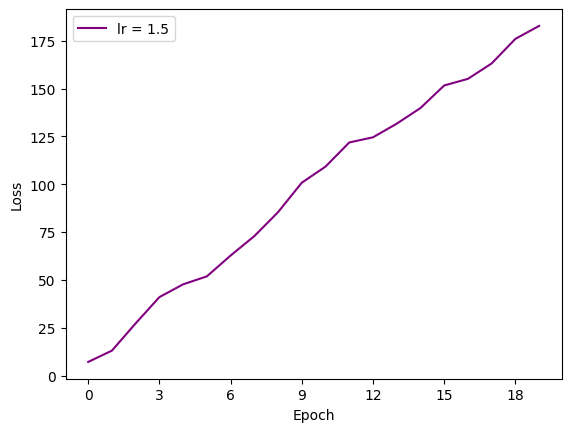

In [20]:
_,loss3,_ = SGD(num_epochs=num_epochs,learning_rate=1.5,batch_size=batch_size)
print(loss3)
plt.plot(np.arange(num_epochs),np.log(loss3),label='lr = 1.5',color='purple')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.legend()
plt.show()


